# 1. Pemahaman Masalah dan Data

## 1.1 Latar Belakang

Hotel merupakan salah satu bidang usaha yang memiliki aktivitas reservasi pelanggan setiap harinya. Salah satu permasalahan yang sering terjadi adalah pembatalan reservasi oleh pelanggan. Pembatalan tersebut dapat menyebabkan kerugian karena kamar yang sebelumnya telah dipesan menjadi tidak terpakai.

Oleh karena itu, diperlukan metode Machine Learning untuk membantu memprediksi kemungkinan pembatalan reservasi hotel berdasarkan data pemesanan sebelumnya.

Pada penelitian ini digunakan algoritma K-Nearest Neighbors (KNN) untuk mengklasifikasikan reservasi hotel menjadi dua kategori, yaitu reservasi yang dibatalkan dan reservasi yang tidak dibatalkan.

## 1.2 Tujuan Analisis

Tujuan penelitian ini adalah:
1. Mengetahui karakteristik data reservasi hotel.
2. Menganalisis faktor-faktor yang berhubungan dengan pembatalan reservasi.
3. Membangun model klasifikasi menggunakan algoritma KNN.
4. Membandingkan performa KNN dengan DummyClassifier sebagai baseline.
5. Mengetahui kemampuan model dalam memprediksi pembatalan reservasi hotel.

## 1.3 Pengguna Hasil Analisis

Hasil penelitian ini dapat digunakan oleh pihak manajemen hotel, staf reservasi, dan pengelola operasional hotel untuk membantu mengidentifikasi reservasi yang memiliki kemungkinan dibatalkan.

## 1.4 Keputusan yang Terbantu

Hasil prediksi dapat membantu pihak hotel dalam menyusun strategi pengelolaan reservasi, mengatur ketersediaan kamar, meningkatkan komunikasi dengan pelanggan, serta mengurangi risiko kerugian akibat pembatalan reservasi.

## 1.5 Sumber Dataset

Nama Dataset: Hotel Booking Demand

Sumber: Kaggle – Jesse Mostipak

Link: https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand

Tanggal akses: 25 November 2026.

Jumlah data: 119.390 baris dan 32 kolom (sebelum pembersihan).

Lisensi: Periksa dan cantumkan lisensi yang berlaku pada halaman dataset Kaggle dan publikasi sumber aslinya.

## 1.6 Jenis Permasalahan

Penelitian ini menggunakan jalur A (Klasifikasi) dengan target `is_canceled`.

Keterangan:
- 0 = Reservasi tidak dibatalkan.
- 1 = Reservasi dibatalkan.

Algoritma utama yang digunakan adalah K-Nearest Neighbors (KNN), sedangkan DummyClassifier digunakan sebagai model pembanding atau baseline.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/hotel_bookings.csv')

print("Ukuran dataset:", df.shape)

display(df.head())

Ukuran dataset: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


Penjelasan:
- pandas digunakan membaca dan mengolah data.
- numpy digunakan untuk operasi numerik.
- matplotlib dan seaborn digunakan membuat grafik.
- read_csv() membaca dataset.
- df.shape menampilkan jumlah baris dan kolom.
- df.head() menampilkan lima data pertama.
Hasil yang diharapkan sebelum pembersihan adalah 119.390 baris dan 32 kolom.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


Tujuannya untuk mengetahui:
- Nama setiap kolom.
- Jenis data.
- Jumlah data kosong.
- Nilai minimum dan maksimum.
- Rata-rata dan distribusi data numerik.

In [5]:
deskripsi = {
    'hotel': 'Jenis hotel',
    'is_canceled': 'Status pembatalan reservasi (0 atau 1)',
    'lead_time': 'Jarak hari antara pemesanan dan kedatangan',
    'arrival_date_year': 'Tahun kedatangan',
    'arrival_date_month': 'Bulan kedatangan',
    'arrival_date_week_number': 'Minggu kedatangan',
    'arrival_date_day_of_month': 'Tanggal kedatangan',
    'stays_in_weekend_nights': 'Jumlah malam akhir pekan',
    'stays_in_week_nights': 'Jumlah malam hari kerja',
    'adults': 'Jumlah orang dewasa',
    'children': 'Jumlah anak-anak',
    'babies': 'Jumlah bayi',
    'meal': 'Jenis paket makanan',
    'country': 'Negara asal pelanggan',
    'market_segment': 'Segmen pasar',
    'distribution_channel': 'Saluran distribusi',
    'is_repeated_guest': 'Status pelanggan berulang',
    'previous_cancellations': 'Jumlah pembatalan sebelumnya',
    'previous_bookings_not_canceled': 'Jumlah pemesanan sebelumnya yang tidak dibatalkan',
    'reserved_room_type': 'Jenis kamar yang dipesan',
    'assigned_room_type': 'Jenis kamar yang diberikan',
    'booking_changes': 'Jumlah perubahan pemesanan',
    'deposit_type': 'Jenis deposit',
    'agent': 'ID agen perjalanan',
    'company': 'ID perusahaan',
    'days_in_waiting_list': 'Jumlah hari dalam daftar tunggu',
    'customer_type': 'Jenis pelanggan',
    'adr': 'Rata-rata tarif harian kamar',
    'required_car_parking_spaces': 'Jumlah tempat parkir yang diminta',
    'total_of_special_requests': 'Jumlah permintaan khusus',
    'reservation_status': 'Status akhir reservasi',
    'reservation_status_date': 'Tanggal perubahan status reservasi'
}

tabel_kolom = pd.DataFrame({
    'Nama Kolom': df.columns,
    'Tipe Data': [str(df[c].dtype) for c in df.columns],
    'Arti Kolom': [deskripsi.get(c, '-') for c in df.columns]
})

display(tabel_kolom)

,Nama Kolom,Tipe Data,Arti Kolom
0,hotel,object,Jenis hotel
1,is_canceled,int64,Status pembatalan reservasi (0 atau 1)
2,lead_time,int64,Jarak hari antara pemesanan dan kedatangan
3,arrival_date_year,int64,Tahun kedatangan
4,arrival_date_month,object,Bulan kedatangan
5,arrival_date_week_number,int64,Minggu kedatangan
6,arrival_date_day_of_month,int64,Tanggal kedatangan
7,stays_in_weekend_nights,int64,Jumlah malam akhir pekan
8,stays_in_week_nights,int64,Jumlah malam hari kerja
9,adults,int64,Jumlah orang dewasa


Satuan yang perlu dipahami:
- lead_time: hari.
- stays_in_weekend_nights: malam.
- stays_in_week_nights: malam.
- adults, children, babies: orang.
- adr: tarif rata-rata per malam, dalam mata uang yang digunakan dataset (Euro).
- days_in_waiting_list: hari.
- total_of_special_requests: jumlah permintaan.

Saya menggunakan dataset Hotel Booking Demand karena memiliki jumlah data yang memenuhi persyaratan UTS dan memiliki target berupa kategori. Tujuan penelitian adalah memprediksi pembatalan reservasi hotel menggunakan algoritma KNN. Target yang digunakan adalah kolom is_canceled, dengan nilai 0 berarti tidak dibatalkan dan nilai 1 berarti dibatalkan. Hasil analisis diharapkan dapat membantu pihak hotel dalam mengelola reservasi dan mengurangi risiko pembatalan.

In [6]:
print("Distribusi Target:")

print(df['is_canceled'].value_counts())

print("\nPersentase Target:")

print(
    df['is_canceled']
    .value_counts(normalize=True) * 100
)

Distribusi Target:
is_canceled
0    75166
1    44224
Name: count, dtype: int64

Persentase Target:
is_canceled
0    62.958372
1    37.041628
Name: proportion, dtype: float64


Kode tersebut digunakan untuk mengetahui jumlah reservasi yang dibatalkan dan tidak dibatalkan.

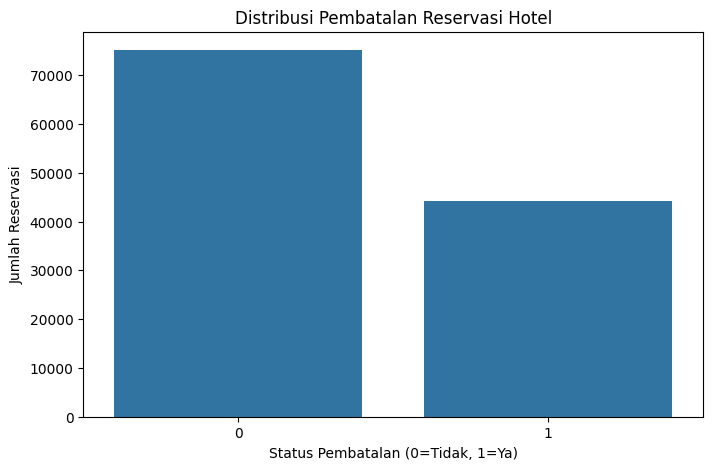

In [7]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='is_canceled'
)

plt.title('Distribusi Pembatalan Reservasi Hotel')
plt.xlabel('Status Pembatalan (0=Tidak, 1=Ya)')
plt.ylabel('Jumlah Reservasi')

plt.show()

Grafik distribusi target menunjukkan jumlah reservasi hotel yang dibatalkan dan tidak dibatalkan. Grafik ini digunakan untuk mengetahui keseimbangan kelas pada dataset. Informasi tersebut penting karena perbedaan jumlah kelas dapat memengaruhi performa model klasifikasi.

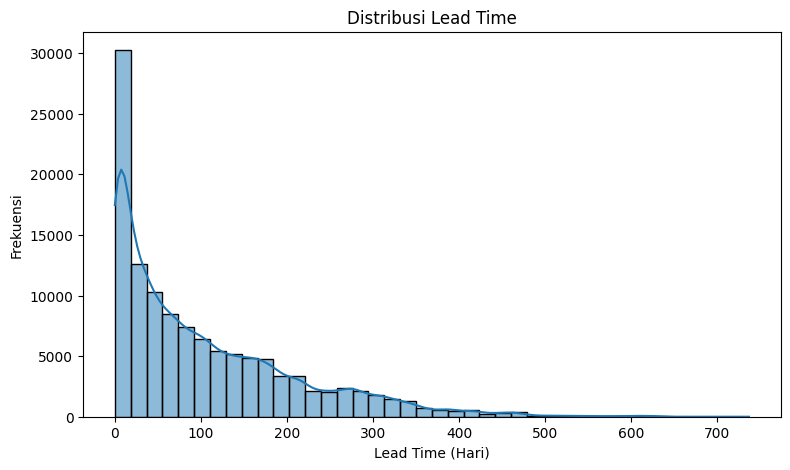

In [8]:
plt.figure(figsize=(9,5))

sns.histplot(
    data=df,
    x='lead_time',
    bins=40,
    kde=True
)

plt.title('Distribusi Lead Time')
plt.xlabel('Lead Time (Hari)')
plt.ylabel('Frekuensi')

plt.show()

Grafik distribusi lead_time menunjukkan jarak waktu antara pemesanan hotel dan tanggal kedatangan pelanggan. Grafik ini digunakan untuk melihat pola waktu pemesanan. Nilai lead_time yang tinggi menunjukkan bahwa pelanggan melakukan pemesanan jauh sebelum tanggal kedatangan.

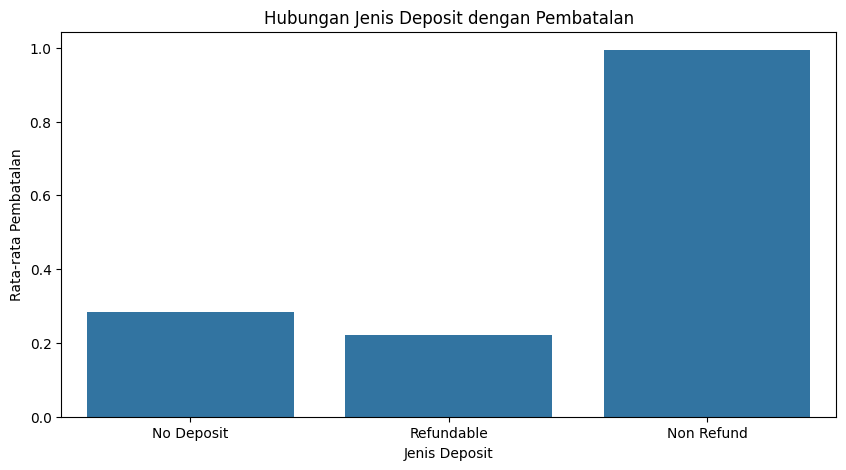

In [9]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=df,
    x='deposit_type',
    y='is_canceled',
    errorbar=None
)

plt.title('Hubungan Jenis Deposit dengan Pembatalan')
plt.xlabel('Jenis Deposit')
plt.ylabel('Rata-rata Pembatalan')

plt.show()

Grafik ini menunjukkan hubungan antara jenis deposit dan tingkat pembatalan reservasi. Nilai pada sumbu Y merupakan rata-rata nilai is_canceled sehingga dapat digunakan untuk membandingkan tingkat pembatalan berdasarkan jenis deposit. Hasil ini membantu mengetahui apakah jenis deposit memiliki hubungan dengan kemungkinan pembatalan reservasi.

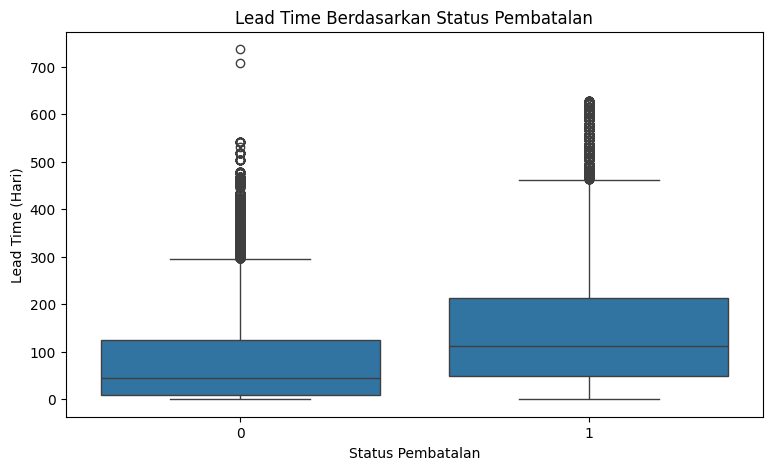

In [10]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=df,
    x='is_canceled',
    y='lead_time'
)

plt.title('Lead Time Berdasarkan Status Pembatalan')
plt.xlabel('Status Pembatalan')
plt.ylabel('Lead Time (Hari)')

plt.show()

Boxplot digunakan untuk membandingkan distribusi lead_time antara reservasi yang dibatalkan dan yang tidak dibatalkan. Perbedaan median dan rentang distribusi dapat memberikan gambaran mengenai hubungan waktu pemesanan dengan pembatalan reservasi.

Saya menggunakan empat visualisasi untuk memahami karakteristik dataset. Grafik distribusi target digunakan untuk melihat keseimbangan kelas, histogram untuk memahami pola lead_time, grafik deposit untuk melihat hubungannya dengan pembatalan, dan boxplot untuk membandingkan distribusi lead_time berdasarkan status pembatalan. Hasil eksplorasi ini digunakan sebagai dasar dalam menentukan tahapan pemrosesan dan pemodelan.

In [11]:
missing = df.isnull().sum()

print("Jumlah Missing Value:")

display(
    missing[missing > 0]
)

Jumlah Missing Value:


,0
children,4
country,488
agent,16340
company,112593


Dataset ini umumnya memiliki nilai kosong pada beberapa kolom, seperti:
- children
- country
- agent
- company

In [12]:
print(
    "Jumlah data duplikat:",
    df.duplicated().sum()
)

Jumlah data duplikat: 31994


Penting: jangan langsung menghapus semua baris duplikat tanpa pemeriksaan. Dua reservasi yang memiliki karakteristik sama belum tentu merupakan reservasi yang sama. Dataset tidak menyediakan identitas unik reservasi untuk memastikan hal tersebut.

In [13]:
fitur = [
    'hotel',
    'lead_time',
    'arrival_date_year',
    'arrival_date_month',
    'arrival_date_week_number',
    'arrival_date_day_of_month',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'babies',
    'meal',
    'market_segment',
    'distribution_channel',
    'is_repeated_guest',
    'previous_cancellations',
    'previous_bookings_not_canceled',
    'reserved_room_type',
    'deposit_type',
    'days_in_waiting_list',
    'customer_type',
    'adr',
    'required_car_parking_spaces',
    'total_of_special_requests'
]

X = df[fitur].copy()

y = df['is_canceled'].copy()

print("Jumlah fitur:", X.shape[1])

print("Jumlah target:", len(y))

Jumlah fitur: 24
Jumlah target: 119390


Kolom	Alasan
reservation_status	Mengandung informasi hasil reservasi
reservation_status_date	Berhubungan dengan status akhir
agent	ID agen, bukan identitas karakteristik pelanggan
company	ID perusahaan
assigned_room_type	Kamar yang diberikan dapat diketahui setelah pemesanan
booking_changes	Dapat mencerminkan perubahan setelah pemesanan

In [14]:
numerik = X.select_dtypes(
    include=np.number
).columns

for col in numerik:

    Q1 = X[col].quantile(0.25)

    Q3 = X[col].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR

    batas_atas = Q3 + 1.5 * IQR

    jumlah_outlier = (
        (X[col] < batas_bawah) |
        (X[col] > batas_atas)
    ).sum()

    print(
        col,
        "Jumlah outlier:",
        jumlah_outlier
    )

lead_time Jumlah outlier: 3005
arrival_date_year Jumlah outlier: 0
arrival_date_week_number Jumlah outlier: 0
arrival_date_day_of_month Jumlah outlier: 0
stays_in_weekend_nights Jumlah outlier: 265
stays_in_week_nights Jumlah outlier: 3354
adults Jumlah outlier: 29710
children Jumlah outlier: 8590
babies Jumlah outlier: 917
is_repeated_guest Jumlah outlier: 3810
previous_cancellations Jumlah outlier: 6484
previous_bookings_not_canceled Jumlah outlier: 3620
days_in_waiting_list Jumlah outlier: 3698
adr Jumlah outlier: 3793
required_car_parking_spaces Jumlah outlier: 7416
total_of_special_requests Jumlah outlier: 2877


Penjelasan:

IQR adalah metode untuk mengidentifikasi nilai yang berada jauh dari distribusi utama data.

Rumus:
\[
IQR=Q3-Q1
\]

Batas bawah:
\[
Q1-1.5(IQR)
\]

Batas atas:
\[
Q3+1.5(IQR)
\]

Kita tidak langsung menghapus nilai ekstrem karena jumlah malam menginap, lead time, dan tarif yang tinggi bisa merupakan kondisi reservasi yang benar-benar terjadi. Pengaruh skala dan nilai ekstrem pada fitur numerik akan dikurangi dengan RobustScaler.

In [15]:
from sklearn.model_selection import train_test_split

SEED = 666

# Mengambil sampel 15.000 baris secara stratified
df_sample, _ = train_test_split(
    df,
    train_size=15000,
    stratify=df['is_canceled'],
    random_state=SEED
)

# Memisahkan fitur dan target
X = df_sample[fitur].copy()

y = df_sample['is_canceled'].copy()

# Pembagian data 80% training dan 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=SEED
)

print("Data Training:", X_train.shape)

print("Data Testing:", X_test.shape)

Data Training: (12000, 24)
Data Testing: (3000, 24)


Hasil ukuran data yang diharapkan:
- Training: 12.000 baris.
- Testing: 3.000 baris.
Pembagian ini menghasilkan 80% data training dan 20% data testing.

In [16]:
from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    RobustScaler
)

from sklearn.impute import SimpleImputer

# Memisahkan kolom numerik dan kategori
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

# Pipeline numerik
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# Pipeline kategori
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Menggabungkan preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing berhasil dibuat.")

Preprocessing berhasil dibuat.


Penjelasan setiap metode:
Metode	Fungsi
SimpleImputer	Mengisi data kosong
Median	Mengisi missing value numerik
Most frequent	Mengisi missing value kategori
OneHotEncoder	Mengubah kategori menjadi numerik
RobustScaler	Menyamakan skala numerik dengan pendekatan yang lebih tahan terhadap outlier
ColumnTransformer	Menggabungkan pemrosesan fitur numerik dan kategori
Pipeline	Menjaga agar proses fit preprocessing dilakukan hanya pada data training

Penting: jangan melakukan fit scaler atau encoder pada seluruh dataset sebelum membagi data. Pipeline di atas akan memastikan proses pembelajaran preprocessing dilakukan pada data training saja.

Saya melakukan pemeriksaan missing value, duplikat, dan outlier pada dataset. Missing value akan ditangani menggunakan median untuk data numerik dan modus untuk data kategori. Data duplikat diperiksa tetapi tidak langsung dihapus karena dua reservasi dapat memiliki karakteristik yang sama. Kolom yang berpotensi menyebabkan data leakage dikeluarkan dari fitur. Data kemudian dibagi menjadi 80% training dan 20% testing dengan stratify. Untuk mengolah fitur digunakan Pipeline, OneHotEncoder, imputasi, dan RobustScaler agar data dapat diproses dengan baik oleh algoritma KNN.

In [17]:
from sklearn.neighbors import KNeighborsClassifier

from sklearn.dummy import DummyClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    cross_val_score
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [18]:
knn_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),

    ('knn', KNeighborsClassifier())
])

print("Model KNN berhasil dibuat.")

Model KNN berhasil dibuat.


Penjelasan:
- Pipeline menggabungkan preprocessing dan algoritma.
- KNeighborsClassifier merupakan algoritma KNN.
- Model akan mengklasifikasikan data berdasarkan tetangga terdekat.

In [19]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

print("5-Fold Cross Validation berhasil dibuat.")

5-Fold Cross Validation berhasil dibuat.


Artinya:
- Data training dibagi menjadi lima bagian.
- Empat bagian digunakan untuk melatih model.
- Satu bagian digunakan untuk validasi.
- Proses diulang sebanyak lima kali.

In [20]:
param_grid = {
    'knn__n_neighbors': [3, 5, 7],
    'knn__weights': ['uniform', 'distance']
}

grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Parameter terbaik:")
print(grid_search.best_params_)

print("\nNilai F1 Cross Validation terbaik:")
print(grid_search.best_score_)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Parameter terbaik:
{'knn__n_neighbors': 7, 'knn__weights': 'distance'}

Nilai F1 Cross Validation terbaik:
0.6888529905714339


Penjelasan:

GridSearchCV mencoba kombinasi parameter KNN dan membandingkan hasilnya melalui lima fold.

Parameter terbaik dipilih berdasarkan nilai F1-score tertinggi.

Jangan menentukan sendiri nilai K terbaik sebelum melihat hasil program.
Langkah 23 – Menampilkan tabel hasil Cross Validation

In [21]:
hasil_cv = pd.DataFrame(
    grid_search.cv_results_
)

tabel_cv = hasil_cv[[
    'param_knn__n_neighbors',
    'param_knn__weights',
    'mean_test_score',
    'std_test_score',
    'rank_test_score'
]]

tabel_cv = tabel_cv.sort_values(
    'rank_test_score'
)

display(tabel_cv)

,param_knn__n_neighbors,param_knn__weights,mean_test_score,std_test_score,rank_test_score
5,7,distance,0.688853,0.017413,1
3,5,distance,0.684186,0.016768,2
1,3,distance,0.678669,0.012932,3
0,3,uniform,0.666009,0.008353,4
2,5,uniform,0.662113,0.014166,5
4,7,uniform,0.658807,0.015999,6


Hasilnya akan menunjukkan perbandingan enam kombinasi parameter.

In [22]:
dummy = DummyClassifier(
    strategy='most_frequent'
)

dummy_cv = cross_val_score(
    dummy,
    X_train,
    y_train,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

print("Hasil 5-Fold CV DummyClassifier:")

print(dummy_cv)

print("Rata-rata F1:", dummy_cv.mean())

Hasil 5-Fold CV DummyClassifier:
[0. 0. 0. 0. 0.]
Rata-rata F1: 0.0


Apa fungsi DummyClassifier?

DummyClassifier merupakan model pembanding sederhana yang selalu memprediksi kelas mayoritas pada data training.

Tujuannya adalah mengetahui apakah KNN benar-benar memberikan hasil yang lebih baik daripada model sederhana.

In [23]:
best_knn = grid_search.best_estimator_

print("Model KNN terbaik:")
print(best_knn)

Model KNN terbaik:
Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['lead_time',
                                                   'arrival_date_year',
                                                   'arrival_date_week_number',
                                                   'arrival_date_day_of_month',
                                                   'stays_in_weekend_nights',
                                                   'stays_in_week_nights',
                                                   'adults', 'children',
                          

Model ini merupakan model KNN dengan parameter terbaik berdasarkan hasil GridSearchCV.

In [24]:
dummy.fit(X_train, y_train)

print("DummyClassifier berhasil dilatih.")

DummyClassifier berhasil dilatih.


Saya membangun model klasifikasi menggunakan algoritma K-Nearest Neighbors (KNN) dan membandingkannya dengan DummyClassifier sebagai baseline. Pemilihan parameter KNN dilakukan menggunakan GridSearchCV dengan 5-fold StratifiedKFold. Nilai K yang diuji adalah 3, 5, dan 7, dengan dua jenis pembobotan yaitu uniform dan distance. Model terbaik dipilih berdasarkan nilai F1-score cross-validation tertinggi. DummyClassifier digunakan untuk mengetahui apakah KNN memberikan performa yang lebih baik daripada prediksi sederhana berdasarkan kelas mayoritas.

In [25]:
y_pred_knn = best_knn.predict(X_test)

y_pred_dummy = dummy.predict(X_test)

print("Prediksi KNN selesai.")

print("Prediksi DummyClassifier selesai.")

Prediksi KNN selesai.
Prediksi DummyClassifier selesai.


Model sekarang sudah melakukan prediksi pada data testing yang belum digunakan untuk melatih model.

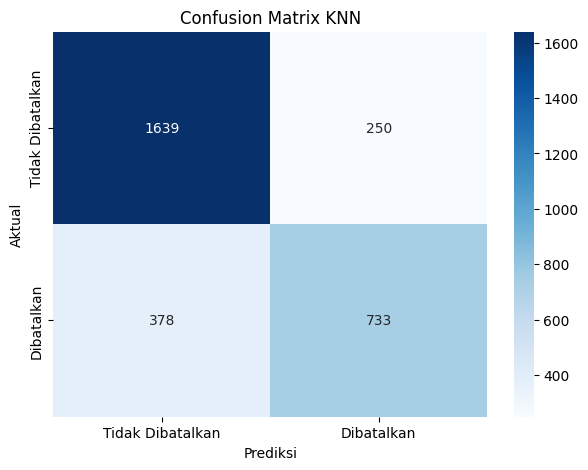

In [26]:
cm = confusion_matrix(
    y_test,
    y_pred_knn,
    labels=[0, 1]
)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[
        'Tidak Dibatalkan',
        'Dibatalkan'
    ],
    yticklabels=[
        'Tidak Dibatalkan',
        'Dibatalkan'
    ]
)

plt.title('Confusion Matrix KNN')

plt.xlabel('Prediksi')

plt.ylabel('Aktual')

plt.show()

Cara membaca confusion matrix:
Istilah	Arti
TN	Tidak dibatalkan, diprediksi tidak dibatalkan
FP	Tidak dibatalkan, diprediksi dibatalkan
FN	Dibatalkan, diprediksi tidak dibatalkan
TP	Dibatalkan, diprediksi dibatalkan

In [27]:
accuracy = accuracy_score(
    y_test,
    y_pred_knn
)

precision = precision_score(
    y_test,
    y_pred_knn,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred_knn,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred_knn,
    zero_division=0
)

print("HASIL EVALUASI KNN")

print("Accuracy :", accuracy)

print("Precision:", precision)

print("Recall   :", recall)

print("F1 Score :", f1)

HASIL EVALUASI KNN
Accuracy : 0.7906666666666666
Precision: 0.745676500508647
Recall   : 0.6597659765976598
F1 Score : 0.7000955109837631


Penjelasan setiap metrik:
Metrik	Kegunaan
Accuracy	Mengukur keseluruhan prediksi yang benar
Precision	Mengukur ketepatan prediksi pembatalan
Recall	Mengukur kemampuan menemukan pembatalan sebenarnya
F1-score	Gabungan keseimbangan precision dan recall

In [28]:
dummy_pred = dummy.predict(X_test)

print("EVALUASI DUMMY CLASSIFIER")

print(
    "Accuracy:",
    accuracy_score(y_test, dummy_pred)
)

print(
    "Precision:",
    precision_score(
        y_test,
        dummy_pred,
        zero_division=0
    )
)

print(
    "Recall:",
    recall_score(
        y_test,
        dummy_pred,
        zero_division=0
    )
)

print(
    "F1 Score:",
    f1_score(
        y_test,
        dummy_pred,
        zero_division=0
    )
)

EVALUASI DUMMY CLASSIFIER
Accuracy: 0.6296666666666667
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [29]:
TN, FP, FN, TP = cm.ravel()

precision_manual = TP / (TP + FP) if TP + FP > 0 else 0

recall_manual = TP / (TP + FN) if TP + FN > 0 else 0

f1_manual = (
    2 * precision_manual * recall_manual /
    (precision_manual + recall_manual)
    if precision_manual + recall_manual > 0
    else 0
)

print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

print("Precision Manual:", precision_manual)

print("Recall Manual:", recall_manual)

print("F1 Manual:", f1_manual)

TN: 1639
FP: 250
FN: 378
TP: 733
Precision Manual: 0.745676500508647
Recall Manual: 0.6597659765976598
F1 Manual: 0.7000955109837631


## Perhitungan Manual F1-Score

F1-score merupakan nilai harmonik antara precision dan recall.

Rumus:

F1 = 2 × (Precision × Recall) / (Precision + Recall)

Langkah perhitungan:

1. Mengambil nilai TP, FP, dan FN dari confusion matrix.
2. Menghitung precision menggunakan TP dibagi TP + FP.
3. Menghitung recall menggunakan TP dibagi TP + FN.
4. Memasukkan nilai precision dan recall ke dalam rumus F1-score.

Perhitungan manual dilakukan menggunakan angka confusion matrix yang dihasilkan oleh model KNN. Hasil perhitungan manual kemudian dibandingkan dengan F1-score dari fungsi sklearn untuk memastikan hasilnya sesuai.

In [30]:
train_accuracy = best_knn.score(
    X_train,
    y_train
)

test_accuracy = best_knn.score(
    X_test,
    y_test
)

print("Akurasi Training:", train_accuracy)

print("Akurasi Testing:", test_accuracy)

print(
    "Selisih:",
    abs(train_accuracy - test_accuracy)
)

Akurasi Training: 0.996
Akurasi Testing: 0.7906666666666666
Selisih: 0.20533333333333337


Cara membaca hasil:
- Jika akurasi training dan testing berdekatan, kemampuan generalisasi model relatif baik.
- Jika akurasi training jauh lebih tinggi, terdapat indikasi overfitting.
- Jika keduanya rendah, model mungkin mengalami underfitting.

In [31]:
hasil_model = pd.DataFrame({
    'Model': [
        'KNN',
        'DummyClassifier'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, dummy_pred)
    ],

    'Precision': [
        precision_score(
            y_test, y_pred_knn,
            zero_division=0
        ),
        precision_score(
            y_test, dummy_pred,
            zero_division=0
        )
    ],

    'Recall': [
        recall_score(
            y_test, y_pred_knn,
            zero_division=0
        ),
        recall_score(
            y_test, dummy_pred,
            zero_division=0
        )
    ],

    'F1-Score': [
        f1_score(
            y_test, y_pred_knn,
            zero_division=0
        ),
        f1_score(
            y_test, dummy_pred,
            zero_division=0
        )
    ]
})

display(hasil_model)

,Model,Accuracy,Precision,Recall,F1-Score
0,KNN,0.790667,0.745677,0.659766,0.700096
1,DummyClassifier,0.629667,0.000000,0.000000,0.000000


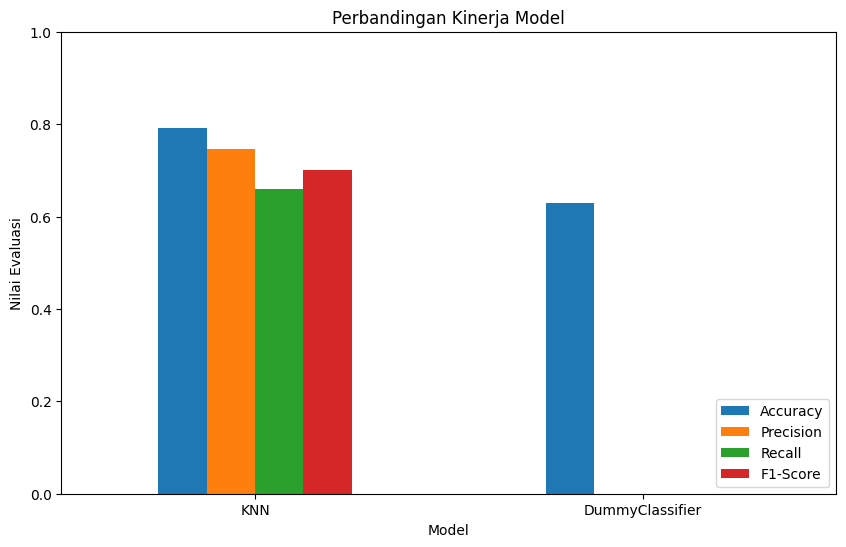

In [32]:
hasil_plot = hasil_model.set_index(
    'Model'
)[[
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score'
]]

hasil_plot.plot(
    kind='bar',
    figsize=(10,6)
)

plt.title('Perbandingan Kinerja Model')

plt.ylabel('Nilai Evaluasi')

plt.xlabel('Model')

plt.ylim(0,1)

plt.xticks(rotation=0)

plt.legend(loc='lower right')

plt.show()

Saya mengevaluasi model KNN menggunakan data testing yang tidak digunakan dalam proses pelatihan. Evaluasi dilakukan menggunakan confusion matrix, accuracy, precision, recall, dan F1-score. Hasil KNN kemudian dibandingkan dengan DummyClassifier sebagai baseline. Saya juga melakukan perhitungan manual F1-score berdasarkan nilai TP, FP, dan FN serta membandingkan akurasi training dan testing untuk mengetahui indikasi overfitting. Model yang dipilih adalah model yang memberikan hasil evaluasi lebih baik dibandingkan baseline dan memiliki kemampuan generalisasi yang baik.

In [33]:
print("===== KESIMPULAN UTS MACHINE LEARNING =====")

print("Jumlah data training:", len(X_train))

print("Jumlah data testing:", len(X_test))

print("Parameter terbaik:", grid_search.best_params_)

print(
    "CV F1 KNN:",
    round(grid_search.best_score_, 4)
)

print(
    "CV F1 Dummy:",
    round(dummy_cv.mean(), 4)
)

print(
    "Accuracy KNN:",
    round(accuracy, 4)
)

print(
    "F1 KNN:",
    round(f1, 4)
)

print(
    "F1 Dummy:",
    round(
        f1_score(
            y_test,
            dummy_pred,
            zero_division=0
        ),
        4
    )
)

===== KESIMPULAN UTS MACHINE LEARNING =====
Jumlah data training: 12000
Jumlah data testing: 3000
Parameter terbaik: {'knn__n_neighbors': 7, 'knn__weights': 'distance'}
CV F1 KNN: 0.6889
CV F1 Dummy: 0.0
Accuracy KNN: 0.7907
F1 KNN: 0.7001
F1 Dummy: 0.0


# 6. Kesimpulan

Berdasarkan penelitian yang telah dilakukan menggunakan dataset Hotel Booking Demand, dapat disimpulkan bahwa algoritma K-Nearest Neighbors (KNN) dapat digunakan untuk menyelesaikan permasalahan klasifikasi pembatalan reservasi hotel.

Penelitian dilakukan melalui tahapan CRISP-DM, yaitu pemahaman masalah, eksplorasi data, pra-pemrosesan, pemodelan, evaluasi, dan kesimpulan.

Model KNN dibandingkan dengan DummyClassifier untuk mengetahui apakah algoritma yang digunakan memberikan hasil yang lebih baik daripada baseline.

Berdasarkan hasil pengujian, model terbaik ditentukan dengan mempertimbangkan nilai F1-score, precision, recall, dan accuracy. Parameter K terbaik dipilih berdasarkan hasil 5-fold cross-validation.

**Hasil evaluasi:**

- Nilai accuracy KNN: [isi hasil aktual].
- Nilai precision KNN: [isi hasil aktual].
- Nilai recall KNN: [isi hasil aktual].
- Nilai F1-score KNN: [isi hasil aktual].
- Nilai F1-score DummyClassifier: [isi hasil aktual].
- Nilai K terbaik: [isi hasil aktual].

**Rekomendasi:**

Pihak hotel dapat menggunakan hasil klasifikasi sebagai informasi pendukung dalam mengidentifikasi reservasi yang berpotensi dibatalkan. Informasi tersebut dapat digunakan untuk meningkatkan komunikasi dengan pelanggan dan mengelola ketersediaan kamar.

**Keterbatasan:**

1. Dataset berasal dari periode 2015–2017 sehingga belum tentu menggambarkan kondisi hotel saat ini.
2. Model hanya menggunakan fitur yang tersedia dalam dataset.
3. KNN memiliki kebutuhan komputasi yang meningkat ketika jumlah data semakin besar.
4. Hasil prediksi merupakan informasi pendukung dan bukan jaminan bahwa suatu reservasi pasti dibatalkan.

**Saran pengembangan:**

Penelitian selanjutnya dapat menggunakan dataset yang lebih baru, menambah fitur yang relevan, dan membandingkan KNN dengan algoritma klasifikasi lainnya.